In [1]:
%load_ext autoreload
%autoreload 2

# CICE + MOM6: real global restart, MOM6 forcing from CESM-POP output

Same wiring as `cice_with_real_restart.ipynb` -- real global CICE restart via
`cice_product_name="cice_restart"` -- but MOM6's own IC/OBC now come from
**`cesm_pop_output`** through its `get_cesm_single_variable_data` access method
instead of the fast synthetic `reference_ocean` product.

That product reads CESM single-variable-per-file (tseries) POP output; its default
`dataset_path` is the CESM-HR FOSI-BGC 0.1-degree run on GLADE campaign
(`g.e22.TL319_t13.G1850ECOIAF_JRA_HR.4p2z.001`, monthly, 1958-2021), so no
`function_args` are needed here. Note the cadence: FOSI `month_1` tseries is
monthly, so a 9-day OBC window is covered by a single monthly snapshot rather
than daily values.

The CICE restart file itself carries no grid of its own (just raw ni/nj/ncat state
on the model's native tripole index space), so `cice_restart` also needs the
matching **CICE tripole grid file** to locate the bounding box's (nj, ni) window
(`find_cice_index_window` in `raw_data_access/datasets/cice_output.py`). This
restart's `(ni, nj)` = (540, 480) match `tx2_3v3_grid.nc`, which is what's used
below.


## Step 0: Paths and imports

Follows the "Fast CrocoDash Case Setup" pattern from the repo's `CLAUDE.md`.

In [2]:
from pathlib import Path

from CrocoDash.grid import Grid
from CrocoDash.topo import Topo
from CrocoDash.vgrid import VGrid
from CrocoDash.case import Case

CESMROOT = Path("~/work/installs/full_regional_cesm").expanduser()
CASENAME = "cice_obc_demo_real_restart_pop"
CASEROOT = (Path("~/croc_cases") / CASENAME).expanduser()
INPUTDIR = (Path("~/scratch/croc_input") / CASENAME).expanduser()

RESTART_PATH = "/glade/u/home/dbailey/b.e30_alpha09b.B1850C_MTso.ne30_t233_wgx3.360.cice.r.0201-01-01-00000.nc"
GRID_PATH = "/glade/campaign/cesm/community/omwg/grids/tx2_3v3_grid.nc"

print(CESMROOT)
print(CASEROOT)
print(INPUTDIR)


/glade/u/home/manishrv/work/installs/full_regional_cesm
/glade/u/home/manishrv/croc_cases/cice_obc_demo_real_restart_pop
/glade/u/home/manishrv/scratch/croc_input/cice_obc_demo_real_restart_pop


## Step 1: Grid, topography, vertical grid

Same Bering Sea domain as the synthetic-data demo -- high enough latitude that this restart's January sea ice actually reaches it.

In [3]:
grid = Grid(
    lenx=15.0,
    leny=10.0,
    resolution=1.0,
    xstart=-170.0,
    ystart=68.0,
    name=CASENAME,
)
topo = Topo(grid, min_depth=10.0, git=False)

vgrid = VGrid.uniform(nk=10, depth=1000.0, name=CASENAME)

In [4]:
bathymetry_path = "/glade/derecho/scratch/manishrv/ice/croc/gebco/GEBCO_2024.nc"
topo.set_from_dataset(
    bathymetry_path = bathymetry_path,
    longitude_coordinate_name="lon",
    latitude_coordinate_name="lat",
    vertical_coordinate_name="elevation",
    depth_method = "xesmf",
    mask_method = "dataset"
)

Slicing source bathymetry to domain: (-170.0, -155.0) x (68.0, 78.0) with buffer 0.5


  Resolution Diagnostics

  Source dataset (GEBCO_2024.nc):
    dlon = 15.0 arcsec  (0.004167°)
    dlat = 15.0 arcsec  (0.004167°)
    dx   ~ 177 m)
    dy   ~ 463 m

  Model grid (T-cell spacing):
    median = 60.33 km
    min    = 51.98 km
    max    = 67.50 km

  Resolution ratio (model dx / dataset dx):
    median = 340.3x
    max    = 380.8x

  Cressman / stats-mask threshold: 12x
  → RECOMMENDED: high_res_regrid()  (Cressman + stats mask)
    Each model cell spans ~340 dataset pixels per side.
    Ocean-aware Cressman interpolation will meaningfully reduce
    land contamination of coastal depth estimates.
Resolution diagnostics recommend using stats-based masking, but xesmf-based depth was requested, so we will do a direct xesmf regrid anyway because it was explicitly requested, but be aware that this may lead to significant land contamination of coastal depth estimates
**NOTE**
            If bathymetry setup fails (e.g. kernel crashes), restart the kernel and edit this cell.


Warning! This was an opionated workflow function that ran multiple steps in sequence. Please edit the mask manually if need be (Some depth methods, like cressman, are mask-aware and may need to be rerun)! 


In [5]:
topo.write_topo("real_topo.nc")

## Step 2: Create the case

Same `CICE` swap as the synthetic-data demo.

In [6]:
case = Case(
    cesmroot=CESMROOT,
    caseroot=CASEROOT,
    inputdir=INPUTDIR,
    compset="1850_DATM%NYF_SLND_CICE_MOM6%REGIONAL_SROF_SGLC_SWAV",
    ocn_grid=grid,
    ocn_topo=topo,
    ocn_vgrid=vgrid,
    atm_grid_name="T62",
    machine="derecho",
    project="ncgd0011",
    override=True,
)
print("CICE in compset:", case.cice_in_compset)

INFO:	initialize:Initializing the visualCaseGen system...


INFO:  csp_solver:CspSolver initialized.


Creating case...

Running the create_newcase tool with the following command:

/glade/u/home/manishrv/work/installs/full_regional_cesm/cime/scripts/create_newcase --compset 1850_DATM%NYF_SLND_CICE_MOM6%REGIONAL_SROF_SGLC_SWAV --res USER_RES --case /glade/u/home/manishrv/croc_cases/cice_obc_demo_real_restart_pop --machine derecho --run-unsupported --project ncgd0011 --non-local 



The create_newcase command was successful.

• Updating case xml variables to include newly generated ocean grid "cice_obc_demo_real_restart_pop" with the following properties:
 nx: 15, ny: 10. ocean mesh: /glade/u/home/manishrv/scratch/croc_input/cice_obc_demo_real_restart_pop/ocnice/ESMF_mesh_cice_obc_demo_real_restart_pop_91cd3a.nc.

./xmlchange OCN_NX=15 --non-local

./xmlchange OCN_NY=10 --non-local



./xmlchange OCN_DOMAIN_MESH=/glade/u/home/manishrv/scratch/croc_input/cice_obc_demo_real_restart_pop/ocnice/ESMF_mesh_cice_obc_demo_real_restart_pop_91cd3a.nc --non-local

./xmlchange ICE_NX=15 --non-local



./xmlchange ICE_NY=10 --non-local



... (7 outputs left out)

Adding parameter changes to user_nl_mom:

  ! Custom Horizonal Grid, Topography, and Vertical Grid
  INPUTDIR = /glade/u/home/manishrv/scratch/croc_input/cice_obc_demo_real_restart_pop/ocnice
  TRIPOLAR_N = False
  REENTRANT_X = False
  REENTRANT_Y = False
  NIGLOBAL = 15
  NJGLOBAL = 10
  GRID_CONFIG = mosaic
  GRID_FILE = ocean_hgrid_cice_obc_demo_real_restart_pop_91cd3a.nc
  TOPO_CONFIG = file
  TOPO_FILE = ocean_topog_cice_obc_demo_real_restart_pop_91cd3a.nc
  MAXIMUM_DEPTH = 3865.0
  MINIMUM_DEPTH = 10.0
  NK = 10
  COORD_CONFIG = none
  ALE_COORDINATE_CONFIG = FILE:ocean_vgrid_cice_obc_demo_real_restart_pop_91cd3a.nc
  REGRIDDING_COORDINATE_MODE = Z*

  ! Timesteps (based on grid resolution)
  DT = 1800.0
  DT_THERM = 1800.0

Adding parameter changes to user_nl_cice:

  grid_format = "nc"
  grid_file = "/glade/u/home/manishrv/scratch/croc_input/cice_obc_demo_real_restart_pop/ocnice/cice_grid_cice_obc_demo_real_restart_pop_91cd3a.nc"
  kmt_file = "/glade/u/home/manishrv/scratch/cr

INFO:	stage:SUCCESS: All stages are complete.


Case created successfully at /glade/u/home/manishrv/croc_cases/cice_obc_demo_real_restart_pop.

To further customize, build, and run the case, navigate to the case directory in your terminal. To create another case, restart the notebook.

./xmlchange MOM6_MEMORY_MODE=dynamic_symmetric --non-local



The following additional configuration options are required to run and must be provided with any listed arguments in configure_forcings:
  - CICE: no arguments
  - conditions: boundaries, product_name, function_name, compset
CICE in compset: True


## Step 3: Configure + process forcings

`product_name`/`function_name` select CESM-POP output for MOM6's IC/OBC;
`cice_function_args` carries the real restart+grid paths through to
`get_cice_restart_subset` as before.


In [7]:
case.configure_forcings(
    date_range=["2020-01-01 00:00:00", "2020-01-09 00:00:00"],
    product_name="cesm_pop_output",
    function_name="get_cesm_single_variable_data",
    cice_product_name="cice_restart",
    cice_function_name="get_cice_restart_subset",
    cice_function_args={"restart_path": RESTART_PATH, "grid_path": GRID_PATH},
    n_halo_cells=2,
)


INFO:CrocoDash.forcing.base:[SKIP] BGC incompatible with compset


INFO:CrocoDash.forcing.base:[SKIP] BGCIC incompatible with compset


INFO:CrocoDash.forcing.base:[SKIP] BGCIronForcing incompatible with compset


INFO:CrocoDash.forcing.base:[SKIP] BGCRiverNutrients incompatible with compset


INFO:CrocoDash.forcing.base:[SKIP] Chl missing args: ['chl_processed_filepath']


INFO:CrocoDash.forcing.base:[REQUIRED] Activating CICE


... (4 outputs left out)

INFO:CrocoDash.forcing.base:Configuring conditions


Adding parameter changes to user_nl_cice:

  ice_ic = 'default'

Adding parameter changes to user_nl_cice:

  ns_boundary_type = 'zero_gradient'

Adding parameter changes to user_nl_cice:

  ew_boundary_type = 'zero_gradient'

Adding parameter changes to user_nl_cice:

  close_boundaries = .false.

Adding parameter changes to user_nl_cice:

  advect = 'upwind'

Adding parameter changes to user_nl_cice:

  restore_ice = .true.

Adding parameter changes to user_nl_cice:

  trestore = 90

Adding parameter changes to user_nl_mom:

  ! Initial conditions
  INIT_LAYERS_FROM_Z_FILE = True
  Z_INIT_ALE_REMAPPING = True
  TEMP_SALT_INIT_VERTICAL_REMAP_ONLY = True
  DEPRESS_INITIAL_SURFACE = True
  VELOCITY_CONFIG = file
  TEMP_SALT_Z_INIT_FILE = init_tracers.nc
  SURFACE_HEIGHT_IC_FILE = init_eta.nc
  VELOCITY_FILE = init_vel.nc
  Z_INIT_FILE_PTEMP_VAR = temp
  Z_INIT_FILE_SALT_VAR = salt
  SURFACE_HEIGHT_IC_VAR = eta_t
  U_IC_VAR = u
  V_IC_VAR = v

  ! Open boundary conditions
  OBC_NUMBER_OF

./xmlchange STOP_OPTION=ndays --non-local



./xmlchange STOP_N=8 --non-local



In [8]:
case.process_forcings()

INFO:CrocoDash.forcing.ic:[CESM_POP_OUTPUT.get_cesm_single_variable_data] Usage: Requires access to the `dataset_path` directory containing CESM single-variable tseries NetCDF files (POP variable/coordinate names). On GLADE, the default path points to a CESM-HR FOSI-BGC run. For CESM2-LENS2, pass `dataset_path='/gdex/data/d651056/CESM2-LE/ocn/proc/tseries/month_1'` and set `member` to the desired ensemble member (e.g. 'LE2-1001.001').


Parsing dataset...
1 file(s) found for variable 'UVEL'
1 file(s) found for variable 'VVEL'
1 file(s) found for variable 'SSH'
1 file(s) found for variable 'TEMP'
1 file(s) found for variable 'SALT'


Subsetted dataset for variable 'UVEL' saved to /glade/u/home/manishrv/scratch/croc_input/cice_obc_demo_real_restart_pop/extract_forcings/raw_data/UVEL_subset_66.5_79.5_-171.5_-153.5_20200101_20200102.nc


Subsetted dataset for variable 'VVEL' saved to /glade/u/home/manishrv/scratch/croc_input/cice_obc_demo_real_restart_pop/extract_forcings/raw_data/VVEL_subset_66.5_79.5_-171.5_-153.5_20200101_20200102.nc


Subsetted dataset for variable 'SSH' saved to /glade/u/home/manishrv/scratch/croc_input/cice_obc_demo_real_restart_pop/extract_forcings/raw_data/SSH_subset_66.5_79.5_-171.5_-153.5_20200101_20200102.nc


Subsetted dataset for variable 'TEMP' saved to /glade/u/home/manishrv/scratch/croc_input/cice_obc_demo_real_restart_pop/extract_forcings/raw_data/TEMP_subset_66.5_79.5_-171.5_-153.5_20200101_20200102.nc


... (53 outputs left out)

INFO:CrocoDash.forcing.obc:MERGE [east]


INFO:CrocoDash.forcing.obc:Saved merged boundary at /glade/u/home/manishrv/scratch/croc_input/cice_obc_demo_real_restart_pop/ocnice/forcing_obc_segment_004.nc


INFO:CrocoDash.forcing.obc:OBC processing complete.


--- xESMF Regridding Info ---
  Source:        nj=76, ni=36, ncat=5  (13,680 points)  [7.70 MB]
  Destination:   ny=14, nx=19  (266 points)  [0.00 MB]
  Method:        nearest_s2d
  Weights:       generating new weights
  Periodic:      False
  Locstream out: False
-----------------------------
Generating regridding weights using xESMF with method 'nearest_s2d'...
--- xESMF Regridding Info ---
  Source:        nj=76, ni=36  (2,736 points)  [0.37 MB]
  Destination:   ny=14, nx=19  (266 points)  [0.00 MB]
  Method:        nearest_s2d
  Weights:       generating new weights
  Periodic:      False
  Locstream out: False
-----------------------------
Generating regridding weights using xESMF with method 'nearest_s2d'...
[timing] ic: 58.5s  bc: 198.6s  cice: 0.6s  total: 257.7s
Case is ready to be built: /glade/u/home/manishrv/croc_cases/cice_obc_demo_real_restart_pop


## Case is set up

MOM6's own IC/OBC are in `case.inputdir / "ocean"` and CICE's `cice_forcing.nc` (covering the domain plus its 2-cell halo) is in `case.inputdir / "sea_ice"`.

In [9]:
print("caseroot:", case.caseroot)
print("inputdir:", case.inputdir)
print("supergrid_path:", case.supergrid_path)

caseroot: /glade/u/home/manishrv/croc_cases/cice_obc_demo_real_restart_pop
inputdir: /glade/u/home/manishrv/scratch/croc_input/cice_obc_demo_real_restart_pop
supergrid_path: /glade/u/home/manishrv/scratch/croc_input/cice_obc_demo_real_restart_pop/ocnice/ocean_hgrid_cice_obc_demo_real_restart_pop_91cd3a.nc


## Inspect CICE's forcing file

The real global restart's January ice state, index-subset to the domain+halo
window and regridded onto it. Like a real CICE restart, this file carries no
`time` dimension at all -- just the single static snapshot.


In [10]:
import xarray as xr

cice_ds = xr.open_dataset(case.inputdir / "sea_ice" / "cice_forcing.nc")
print("dims:", dict(cice_ds.sizes))
print("domain (T-cells):", grid.tlon.shape, "-> with halo:", (cice_ds.sizes["ny"], cice_ds.sizes["nx"]))
print("total sea ice area (aicen sum):", float(cice_ds["aicen"].sum()))


dims: {'ny': 14, 'nx': 19, 'ncat': 5}
domain (T-cells): (10, 15) -> with halo: (14, 19)
total sea ice area (aicen sum): 213.51231967917968


## Plot real ice concentration on the expanded grid

Summed across the 5 thickness categories -- real spatial structure (a
concentration front, not a uniform taper) since this is an actual January CICE
state.


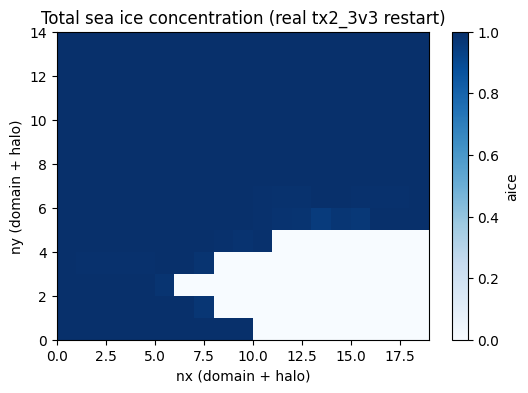

In [11]:
import matplotlib.pyplot as plt

aice_total = cice_ds["aicen"].sum(dim="ncat")
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.pcolormesh(aice_total.values, cmap="Blues", vmin=0, vmax=1)
ax.set_title("Total sea ice concentration (real tx2_3v3 restart)")
ax.set_xlabel("nx (domain + halo)")
ax.set_ylabel("ny (domain + halo)")
fig.colorbar(im, ax=ax, label="aice")
plt.show()
